# 07 — p5986 LSTM+CNN prediction of TTF and shear stress

This notebook verified the one-point prediction task from Laurenti et al. (2022) `generic_prediction.ipynb` and addresses research risks in the original GitHub implementation:

- Scaler is fitted only on training rows; validation/test are only transformed.
- No min/max normalization using the test set itself.
- Training callbacks monitor only validation; test is used only in the final section.
- Split follows the fixed complete seismic cycles (63/7/30) from Notebook 06.
- The two targets are trained separately: non-negative output for TTF, linear output for shear stress.
- Compares sensor 9, two sensors selected validation-only, and all 12 sensors.
- Mean, lag persistence, instantaneous XGBoost, and LSTM+CNN use the same test rows.

Architecture: BatchNormalization → LSTM(128) → Conv1D(128,84,64; kernel 2) → Flatten → Dense(64,32) → Dense(1).


In [ ]:
# Google Colab setup
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import os, json, math, re, time, gc, hashlib, shutil, warnings
import numpy as np
import pandas as pd
import h5py

P5986_ROOT = Path(os.environ.get(
    'P5986_ROOT',
    '/content/drive/MyDrive/MLStressDrop/p5986',
))
AC_DIR = P5986_ROOT / 'acData'
RUN1_DIR = AC_DIR / 'run1'
MAT_DIR = AC_DIR / 'MatFiles'
OUT_DIR = P5986_ROOT / 'colab_outputs_p5986'
OUT_DIR.mkdir(parents=True, exist_ok=True)

assert P5986_ROOT.exists(), (
    f'Cannot find {P5986_ROOT}. Edit P5986_ROOT or add a Drive shortcut.'
)
print('P5986_ROOT =', P5986_ROOT)
print('OUT_DIR    =', OUT_DIR)

import random
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
import joblib
import tensorflow as tf
from tensorflow import keras

print('TensorFlow:', tf.__version__)
print('GPU devices:', tf.config.list_physical_devices('GPU'))


Mounted at /content/drive
P5986_ROOT = /content/drive/MyDrive/MLStressDrop/p5986
OUT_DIR    = /content/drive/MyDrive/MLStressDrop/p5986/colab_outputs_p5986
TensorFlow: 2.20.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
# Configuration — test remains untouched by all choices below.
RANDOM_SEED = 1234
SEQUENCE_LENGTH = 200
BATCH_SIZE = 256
MAX_EPOCHS = 120
EARLY_STOPPING_PATIENCE = 20
REDUCE_LR_PATIENCE = 5
LEARNING_RATE = 1e-3
RUN_SENSOR_EXPERIMENTS = ['sensor9', 'selected_pair', 'all12']
TARGETS = ['ttf_to_failure_start_s', 'mean_shear_stress_mpa']

# Optional validation-only sweep. This can be expensive and never reads test rows.
RUN_HYPERPARAMETER_SWEEP = False
SWEEP_SEQUENCE_LENGTHS = [100, 150, 200, 300, 400]
SWEEP_LEARNING_RATES = [3e-4, 1e-3, 3e-3, 8e-3]
SWEEP_MAX_EPOCHS = 40

# If physical sensor locations become known, enter exactly two zero-based indices.
PAIR_SENSOR_INDICES = None
MAX_PROXY_TRAIN_SEQUENCES = 20_000
FINAL_TEST_UNLOCK = True  # Run the final-test cell only after configuration is frozen.

np.random.seed(RANDOM_SEED)
random.seed(RANDOM_SEED)
tf.keras.utils.set_random_seed(RANDOM_SEED)
try:
    tf.config.experimental.enable_op_determinism()
except Exception as exc:
    print('Deterministic ops unavailable:', exc)

DB_PARQUET = OUT_DIR / '06_multisensor_variance_database_p5986_run1.parquet'
DB_CSV = OUT_DIR / '06_multisensor_variance_database_p5986_run1.csv.gz'
DB_META = OUT_DIR / '06_multisensor_variance_metadata_p5986_run1.json'
assert DB_PARQUET.exists() or DB_CSV.exists(), 'Run Notebook 06 first.'


## 1. Load and validate Notebook 06 database


In [ ]:
database = pd.read_parquet(DB_PARQUET) if DB_PARQUET.exists() else pd.read_csv(DB_CSV)
database = database.sort_values('window_center_s').reset_index(drop=True)
feature_columns = [f'log10_ae_var_sensor_{s}' for s in range(12)]
required = set(feature_columns + TARGETS + [
    'window_start_s', 'window_center_s', 'window_end_s',
    'step_seconds', 'cycle_id', 'split',
])
missing = required.difference(database.columns)
if missing:
    raise KeyError(f'Missing database columns: {sorted(missing)}')
if not np.all(np.diff(database['window_center_s']) > 0):
    raise ValueError('Database time must be strictly increasing.')
if not database[feature_columns + TARGETS].notna().all().all():
    raise ValueError('Features or targets contain NaN.')
assert set(database['split']) == {'train', 'validation', 'test'}

feature_matrix = database[feature_columns].to_numpy(np.float32)
target_arrays = {target: database[target].to_numpy(np.float32) for target in TARGETS}
time_values = database['window_center_s'].to_numpy(np.float64)
step_seconds = float(np.median(database['step_seconds']))
with open(DB_META, 'r', encoding='utf-8') as stream:
    database_metadata = json.load(stream)

display(database.groupby('split').agg(
    rows=('window_center_s', 'size'),
    cycles=('cycle_id', 'nunique'),
    start=('window_start_s', 'min'),
    end=('window_end_s', 'max'),
))
print('sequence duration ≈', SEQUENCE_LENGTH * step_seconds, 's')


,rows,cycles,start,end
split,,,,
test,18649,94,2903.1122,3158.7268
train,38883,194,2311.5188,2844.3392
validation,4279,21,2844.3529,2903.0985


sequence duration ≈ 2.7399999999999998 s


## 2. Build causal sequence endpoints without crossing a split or a data gap


In [ ]:
def contiguous_blocks(indices, max_gap_seconds):
    indices = np.asarray(indices, dtype=np.int64)
    if not len(indices):
        return []
    cuts = np.flatnonzero(
        (np.diff(indices) != 1)
        | (np.diff(time_values[indices]) > max_gap_seconds)
    ) + 1
    return [block for block in np.split(indices, cuts) if len(block)]

def endpoints_for_split(split_name, sequence_length):
    rows = np.flatnonzero(database['split'].to_numpy() == split_name)
    endpoints = []
    for block in contiguous_blocks(rows, max_gap_seconds=1.5 * step_seconds):
        if len(block) >= sequence_length:
            endpoints.append(block[sequence_length - 1:])
    return np.concatenate(endpoints) if endpoints else np.array([], dtype=np.int64)

endpoints = {
    split: endpoints_for_split(split, SEQUENCE_LENGTH)
    for split in ['train', 'validation', 'test']
}
if any(len(v) == 0 for v in endpoints.values()):
    raise ValueError({k: len(v) for k, v in endpoints.items()})
print({k: len(v) for k, v in endpoints.items()})

# Strict boundary audit: every sequence row belongs to the same split as its endpoint.
split_array = database['split'].to_numpy()
for split_name, end_rows in endpoints.items():
    for endpoint in end_rows[::max(1, len(end_rows) // 1000)]:
        sequence_rows = np.arange(endpoint - SEQUENCE_LENGTH + 1, endpoint + 1)
        assert np.all(split_array[sequence_rows] == split_name)


{'train': 38684, 'validation': 4080, 'test': 18450}


## 3. Choose the two-sensor experiment using training/validation only


In [ ]:
def evenly_spaced_subset(values, maximum):
    values = np.asarray(values, dtype=np.int64)
    if len(values) <= maximum:
        return values
    positions = np.linspace(0, len(values) - 1, maximum).round().astype(int)
    return values[positions]

def sequence_matrix_for_sensor(end_rows, sensor, sequence_length):
    offsets = np.arange(sequence_length - 1, -1, -1, dtype=np.int64)
    row_matrix = end_rows[:, None] - offsets[None, :]
    return feature_matrix[row_matrix, sensor]

if PAIR_SENSOR_INDICES is None:
    proxy_train_endpoints = evenly_spaced_subset(
        endpoints['train'], MAX_PROXY_TRAIN_SEQUENCES
    )
    proxy_val_endpoints = endpoints['validation']
    ranking_rows = []
    for sensor in range(12):
        X_train_proxy = sequence_matrix_for_sensor(
            proxy_train_endpoints, sensor, SEQUENCE_LENGTH
        )
        X_val_proxy = sequence_matrix_for_sensor(
            proxy_val_endpoints, sensor, SEQUENCE_LENGTH
        )
        scaler = StandardScaler()
        X_train_proxy = scaler.fit_transform(X_train_proxy)
        X_val_proxy = scaler.transform(X_val_proxy)
        row = {'sensor_zero_based': sensor}
        scores = []
        for target in TARGETS:
            model = Ridge(alpha=1.0)
            model.fit(X_train_proxy, target_arrays[target][proxy_train_endpoints])
            prediction = model.predict(X_val_proxy)
            score = r2_score(target_arrays[target][proxy_val_endpoints], prediction)
            row[f'validation_r2_{target}'] = float(score)
            scores.append(score)
        row['validation_r2_mean'] = float(np.mean(scores))
        ranking_rows.append(row)
    sensor_ranking = pd.DataFrame(ranking_rows).sort_values(
        'validation_r2_mean', ascending=False
    ).reset_index(drop=True)
    PAIR_SENSOR_INDICES = sensor_ranking.head(2)['sensor_zero_based'].astype(int).tolist()
else:
    if len(PAIR_SENSOR_INDICES) != 2 or len(set(PAIR_SENSOR_INDICES)) != 2:
        raise ValueError('PAIR_SENSOR_INDICES must contain two distinct sensors.')
    if not set(PAIR_SENSOR_INDICES).issubset(range(12)):
        raise ValueError(PAIR_SENSOR_INDICES)
    sensor_ranking = pd.DataFrame({
        'sensor_zero_based': PAIR_SENSOR_INDICES,
        'selection': 'physical/user override',
    })

SENSOR_SETS = {
    'sensor9': [9],
    'selected_pair': list(PAIR_SENSOR_INDICES),
    'all12': list(range(12)),
}
print('selected pair:', PAIR_SENSOR_INDICES)
display(sensor_ranking)
sensor_ranking.to_csv(OUT_DIR / '07_validation_only_sensor_ranking_p5986.csv', index=False)


selected pair: [6, 10]


,sensor_zero_based,validation_r2_ttf_to_failure_start_s,validation_r2_mean_shear_stress_mpa,validation_r2_mean
0,6,0.444952,0.841391,0.643171
1,10,0.429981,0.853928,0.641955
2,7,0.438581,0.845268,0.641925
3,11,0.433471,0.847566,0.640519
4,0,0.435705,0.843117,0.639411
5,2,0.439858,0.835098,0.637478
6,4,0.434761,0.836877,0.635819
7,5,0.438131,0.832144,0.635137
8,1,0.429120,0.836272,0.632696
9,8,0.418396,0.845308,0.631852


## 4. Memory-efficient Keras sequence loader and LSTM+CNN model

The generator only assembles `[batch, sequence_length, sensors]` for each batch, avoiding creating the approximately 600 MB all-12 sliding-window tensor all at once.

In [ ]:
class MinMax1D:
    def fit(self, values):
        values = np.asarray(values, dtype=np.float64)
        self.minimum = float(np.min(values))
        self.maximum = float(np.max(values))
        self.scale = max(self.maximum - self.minimum, 1e-12)
        return self
    def transform(self, values):
        return (np.asarray(values) - self.minimum) / self.scale
    def inverse_transform(self, values):
        return np.asarray(values) * self.scale + self.minimum
    def as_dict(self):
        return {'minimum': self.minimum, 'maximum': self.maximum, 'scale': self.scale}

class WindowSequence(keras.utils.Sequence):
    def __init__(self, end_rows, sensor_indices, target_values, target_scaler,
                 feature_minimum, feature_scale, sequence_length, batch_size,
                 shuffle=False, seed=1234, **kwargs):
        super().__init__(**kwargs)
        self.end_rows = np.asarray(end_rows, dtype=np.int64).copy()
        self.sensor_indices = np.asarray(sensor_indices, dtype=np.int64)
        self.target_values = target_values
        self.target_scaler = target_scaler
        self.feature_minimum = np.asarray(feature_minimum, dtype=np.float32)
        self.feature_scale = np.asarray(feature_scale, dtype=np.float32)
        self.sequence_length = int(sequence_length)
        self.batch_size = int(batch_size)
        self.shuffle = bool(shuffle)
        self.rng = np.random.default_rng(seed)
        self.offsets = np.arange(self.sequence_length - 1, -1, -1, dtype=np.int64)
        self.on_epoch_end()

    def __len__(self):
        return math.ceil(len(self.end_rows) / self.batch_size)

    def __getitem__(self, batch_index):
        selected = self.order[
            batch_index * self.batch_size:(batch_index + 1) * self.batch_size
        ]
        batch_end = self.end_rows[selected]
        rows = batch_end[:, None] - self.offsets[None, :]
        X = feature_matrix[rows][:, :, self.sensor_indices]
        X = (X - self.feature_minimum) / self.feature_scale
        y = self.target_scaler.transform(self.target_values[batch_end]).reshape(-1, 1)
        return X.astype(np.float32), y.astype(np.float32)

    def on_epoch_end(self):
        self.order = np.arange(len(self.end_rows))
        if self.shuffle:
            self.rng.shuffle(self.order)

def fit_feature_scaler(sensor_indices):
    train_rows = np.flatnonzero(database['split'].to_numpy() == 'train')
    values = feature_matrix[train_rows][:, sensor_indices]
    minimum = np.min(values, axis=0).astype(np.float32)
    maximum = np.max(values, axis=0).astype(np.float32)
    scale = np.maximum(maximum - minimum, 1e-12).astype(np.float32)
    return minimum, maximum, scale

def build_lstm_cnn(sequence_length, n_features, target_name, learning_rate):
    inputs = keras.Input(shape=(sequence_length, n_features), name='ae_log_variance_history')
    x = keras.layers.BatchNormalization(name='input_batch_norm')(inputs)
    x = keras.layers.LSTM(128, return_sequences=True, name='lstm_128')(x)
    x = keras.layers.Conv1D(128, 2, padding='same', activation='relu', name='conv_128')(x)
    x = keras.layers.Conv1D(84, 2, padding='same', activation='relu', name='conv_84')(x)
    x = keras.layers.Conv1D(64, 2, padding='same', activation='relu', name='conv_64')(x)
    x = keras.layers.Flatten(name='flatten')(x)
    x = keras.layers.Dense(64, activation='relu', name='dense_64')(x)
    x = keras.layers.Dense(32, activation='relu', name='dense_32')(x)
    output_activation = 'relu' if target_name == 'ttf_to_failure_start_s' else 'linear'
    outputs = keras.layers.Dense(1, activation=output_activation, name='regressor')(x)
    model = keras.Model(inputs=inputs, outputs=outputs, name=f'p5986_lstm_cnn_{target_name}')
    model.compile(
        optimizer=keras.optimizers.Nadam(learning_rate=learning_rate),
        loss='mean_squared_error',
    )
    return model

def make_generators(sensor_indices, target_name, sequence_length, batch_size):
    feature_min, feature_max, feature_scale = fit_feature_scaler(sensor_indices)
    target_scaler = MinMax1D().fit(target_arrays[target_name][endpoints_for_split('train', sequence_length)])
    split_endpoints = {
        split: endpoints_for_split(split, sequence_length)
        for split in ['train', 'validation', 'test']
    }
    generators = {
        split: WindowSequence(
            split_endpoints[split], sensor_indices, target_arrays[target_name], target_scaler,
            feature_min, feature_scale, sequence_length, batch_size,
            shuffle=(split == 'train'), seed=RANDOM_SEED,
        )
        for split in split_endpoints
    }
    scaler_info = {
        'feature_minimum': feature_min.tolist(),
        'feature_maximum': feature_max.tolist(),
        'feature_scale': feature_scale.tolist(),
        'target': target_scaler.as_dict(),
    }
    return generators, split_endpoints, target_scaler, scaler_info


## 5. Optional validation-only sequence-length / learning-rate sweep

Default: NaN


In [ ]:
sweep_results = []
if RUN_HYPERPARAMETER_SWEEP:
    for candidate_length in SWEEP_SEQUENCE_LENGTHS:
        for candidate_lr in SWEEP_LEARNING_RATES:
            tf.keras.backend.clear_session()
            generators, _, _, _ = make_generators(
                [9], 'ttf_to_failure_start_s', candidate_length, BATCH_SIZE
            )
            model = build_lstm_cnn(candidate_length, 1, 'ttf_to_failure_start_s', candidate_lr)
            history = model.fit(
                generators['train'],
                validation_data=generators['validation'],
                epochs=SWEEP_MAX_EPOCHS,
                verbose=0,
                callbacks=[
                    keras.callbacks.EarlyStopping(
                        monitor='val_loss', patience=8, restore_best_weights=True
                    ),
                    keras.callbacks.ReduceLROnPlateau(
                        monitor='val_loss', factor=0.5, patience=4, min_lr=1e-6
                    ),
                ],
            )
            sweep_results.append({
                'sequence_length': candidate_length,
                'learning_rate': candidate_lr,
                'best_validation_mse_scaled': float(np.min(history.history['val_loss'])),
                'epochs': len(history.history['loss']),
            })
            print(sweep_results[-1])
    sweep_results = pd.DataFrame(sweep_results).sort_values('best_validation_mse_scaled')
    display(sweep_results)
    sweep_results.to_csv(OUT_DIR / '07_validation_only_hyperparameter_sweep_p5986.csv', index=False)
else:
    print('Sweep disabled; using sequence_length=', SEQUENCE_LENGTH, 'learning_rate=', LEARNING_RATE)


Sweep disabled; using sequence_length= 200 learning_rate= 0.001


## 6. Train six independent prediction models using train/validation only

In [ ]:
training_manifest = []
scaler_manifest = {}

for experiment_key in RUN_SENSOR_EXPERIMENTS:
    sensor_indices = SENSOR_SETS[experiment_key]
    for target_name in TARGETS:
        tf.keras.backend.clear_session()
        generators, split_endpoints, target_scaler, scaler_info = make_generators(
            sensor_indices, target_name, SEQUENCE_LENGTH, BATCH_SIZE
        )
        model = build_lstm_cnn(
            SEQUENCE_LENGTH, len(sensor_indices), target_name, LEARNING_RATE
        )
        local_model = Path('/content') / f'07_lstm_cnn_{experiment_key}_{target_name}.keras'
        callbacks = [
            keras.callbacks.ModelCheckpoint(
                local_model,
                monitor='val_loss',
                mode='min',
                save_best_only=True,
            ),
            keras.callbacks.EarlyStopping(
                monitor='val_loss',
                patience=EARLY_STOPPING_PATIENCE,
                mode='min',
                restore_best_weights=True,
            ),
            keras.callbacks.ReduceLROnPlateau(
                monitor='val_loss',
                factor=0.5,
                patience=REDUCE_LR_PATIENCE,
                min_delta=1e-4,
                min_lr=1e-6,
            ),
            keras.callbacks.TerminateOnNaN(),
        ]
        print('\nTraining:', experiment_key, target_name, 'sensors=', sensor_indices)
        print('parameters:', model.count_params())
        history = model.fit(
            generators['train'],
            validation_data=generators['validation'],
            epochs=MAX_EPOCHS,
            callbacks=callbacks,
            verbose=1,
        )
        best_model = keras.models.load_model(local_model)
        history_frame = pd.DataFrame(history.history)
        history_path = OUT_DIR / f'07_history_{experiment_key}_{target_name}.csv'
        history_frame.to_csv(history_path, index=False)
        drive_model = OUT_DIR / local_model.name
        shutil.copy2(local_model, drive_model)

        key = f'{experiment_key}__{target_name}'
        scaler_manifest[key] = scaler_info
        training_manifest.append({
            'experiment': experiment_key,
            'target': target_name,
            'sensor_indices_zero_based': sensor_indices,
            'sequence_length': SEQUENCE_LENGTH,
            'sequence_duration_s': SEQUENCE_LENGTH * step_seconds,
            'model_parameters': int(best_model.count_params()),
            'epochs_completed': len(history_frame),
            'best_validation_mse_scaled': float(history_frame['val_loss'].min()),
            'model_path': str(drive_model),
            'history_path': str(history_path),
        })
        print(training_manifest[-1])
        del model, best_model, generators
        gc.collect()

training_manifest = pd.DataFrame(training_manifest)
training_manifest.to_csv(OUT_DIR / '07_training_manifest_p5986.csv', index=False)
display(training_manifest)



Training: sensor9 ttf_to_failure_start_s sensors= [9]
parameters: 953241
Epoch 1/120
152/152 ━━━━━━━━━━━━━━━━━━━━ 14s 53ms/step - loss: 0.0268 - val_loss: 0.0586 - learning_rate: 0.0010
Epoch 2/120
152/152 ━━━━━━━━━━━━━━━━━━━━ 6s 40ms/step - loss: 0.0152 - val_loss: 0.0484 - learning_rate: 0.0010
Epoch 3/120
152/152 ━━━━━━━━━━━━━━━━━━━━ 6s 43ms/step - loss: 0.0124 - val_loss: 0.0213 - learning_rate: 0.0010
Epoch 4/120
152/152 ━━━━━━━━━━━━━━━━━━━━ 10s 41ms/step - loss: 0.0101 - val_loss: 0.0150 - learning_rate: 0.0010
Epoch 5/120
152/152 ━━━━━━━━━━━━━━━━━━━━ 7s 43ms/step - loss: 0.0086 - val_loss: 0.0138 - learning_rate: 0.0010
Epoch 6/120
152/152 ━━━━━━━━━━━━━━━━━━━━ 6s 41ms/step - loss: 0.0069 - val_loss: 0.0135 - learning_rate: 0.0010
Epoch 7/120
152/152 ━━━━━━━━━━━━━━━━━━━━ 10s 41ms/step - loss: 0.0058 - val_loss: 0.0148 - learning_rate: 0.0010
Epoch 8/120
152/152 ━━━━━━━━━━━━━━━━━━━━ 7s 47ms/step - loss: 0.0048 - val_loss: 0.0129 - learning_rate: 0.0010
Epoch 9/120
152/152 ━━━━━━━

,experiment,target,sensor_indices_zero_based,sequence_length,sequence_duration_s,model_parameters,epochs_completed,best_validation_mse_scaled,model_path,history_path
0,sensor9,ttf_to_failure_start_s,[9],200,2.74,953241,29,0.012342,/content/drive/MyDrive/MLStressDrop/p5986/cola...,/content/drive/MyDrive/MLStressDrop/p5986/cola...
1,sensor9,mean_shear_stress_mpa,[9],200,2.74,953241,36,0.001356,/content/drive/MyDrive/MLStressDrop/p5986/cola...,/content/drive/MyDrive/MLStressDrop/p5986/cola...
2,selected_pair,ttf_to_failure_start_s,"[6, 10]",200,2.74,953757,29,0.011893,/content/drive/MyDrive/MLStressDrop/p5986/cola...,/content/drive/MyDrive/MLStressDrop/p5986/cola...
3,selected_pair,mean_shear_stress_mpa,"[6, 10]",200,2.74,953757,34,0.000903,/content/drive/MyDrive/MLStressDrop/p5986/cola...,/content/drive/MyDrive/MLStressDrop/p5986/cola...
4,all12,ttf_to_failure_start_s,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]",200,2.74,958917,25,0.011812,/content/drive/MyDrive/MLStressDrop/p5986/cola...,/content/drive/MyDrive/MLStressDrop/p5986/cola...
5,all12,mean_shear_stress_mpa,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]",200,2.74,958917,38,0.000879,/content/drive/MyDrive/MLStressDrop/p5986/cola...,/content/drive/MyDrive/MLStressDrop/p5986/cola...


## 7. Final locked test: LSTM+CNN, XGBoost, mean, and lag-persistence baselines

In [ ]:
if not FINAL_TEST_UNLOCK:
    raise RuntimeError('FINAL_TEST_UNLOCK=False. Freeze all choices before final test.')

try:
    from xgboost import XGBRegressor
    HAVE_XGBOOST = True
except Exception as exc:
    HAVE_XGBOOST = False
    print('XGBoost unavailable; skipping matched baseline:', exc)

def metric_row(y_true, y_pred, model_name, experiment_key, target_name):
    return {
        'model': model_name,
        'experiment': experiment_key,
        'target': target_name,
        'r2': float(r2_score(y_true, y_pred)),
        'mae': float(mean_absolute_error(y_true, y_pred)),
        'rmse': float(mean_squared_error(y_true, y_pred) ** 0.5),
        'n_test': int(len(y_true)),
    }

final_metrics = []
prediction_frames = []
xgb_models = []

for record in training_manifest.to_dict('records'):
    experiment_key = record['experiment']
    target_name = record['target']
    sensor_indices = SENSOR_SETS[experiment_key]
    generators, split_endpoints, target_scaler, scaler_info = make_generators(
        sensor_indices, target_name, SEQUENCE_LENGTH, BATCH_SIZE
    )
    test_end = split_endpoints['test']
    train_end = split_endpoints['train']
    validation_end = split_endpoints['validation']
    y_true = target_arrays[target_name][test_end].astype(np.float64)

    model = keras.models.load_model(record['model_path'])
    y_scaled = model.predict(generators['test'], verbose=0).reshape(-1)
    y_lstm = target_scaler.inverse_transform(y_scaled)
    if target_name == 'ttf_to_failure_start_s':
        y_lstm = np.maximum(y_lstm, 0.0)
    final_metrics.append(metric_row(
        y_true, y_lstm, 'LSTM+CNN', experiment_key, target_name
    ))

    train_mean = float(np.mean(target_arrays[target_name][train_end]))
    y_mean = np.full_like(y_true, train_mean)
    final_metrics.append(metric_row(
        y_true, y_mean, 'train_mean', experiment_key, target_name
    ))

    previous_rows = test_end - 1
    y_previous = target_arrays[target_name][previous_rows].astype(np.float64)
    if target_name == 'ttf_to_failure_start_s':
        dt = time_values[test_end] - time_values[previous_rows]
        y_persistence = np.maximum(y_previous - dt, 0.0)
    else:
        y_persistence = y_previous
    final_metrics.append(metric_row(
        y_true, y_persistence, 'lag_persistence', experiment_key, target_name
    ))

    y_xgb = np.full_like(y_true, np.nan)
    if HAVE_XGBOOST:
        X_train = feature_matrix[train_end][:, sensor_indices]
        X_validation = feature_matrix[validation_end][:, sensor_indices]
        X_test = feature_matrix[test_end][:, sensor_indices]
        xgb = XGBRegressor(
            n_estimators=500,
            max_depth=4,
            learning_rate=0.03,
            subsample=0.8,
            colsample_bytree=1.0,
            objective='reg:squarederror',
            random_state=RANDOM_SEED,
            n_jobs=-1,
        )
        # Only train rows are fitted; validation score is recorded but never optimized on test.
        xgb.fit(X_train, target_arrays[target_name][train_end])
        validation_prediction = xgb.predict(X_validation)
        validation_r2 = r2_score(
            target_arrays[target_name][validation_end], validation_prediction
        )
        y_xgb = xgb.predict(X_test)
        final_metrics.append(metric_row(
            y_true, y_xgb, 'XGBoost_instantaneous', experiment_key, target_name
        ) | {'validation_r2': float(validation_r2)})
        xgb_path = OUT_DIR / f'07_xgboost_same_split_{experiment_key}_{target_name}.joblib'
        joblib.dump(xgb, xgb_path)
        xgb_models.append(str(xgb_path))

    frame = database.loc[test_end, [
        'window_id', 'window_center_s', 'cycle_id', 'split'
    ]].copy()
    frame['experiment'] = experiment_key
    frame['target'] = target_name
    frame['y_true'] = y_true
    frame['prediction_lstm_cnn'] = y_lstm
    frame['prediction_train_mean'] = y_mean
    frame['prediction_lag_persistence'] = y_persistence
    frame['prediction_xgboost_instantaneous'] = y_xgb
    prediction_frames.append(frame)
    del model, generators

final_metrics = pd.DataFrame(final_metrics)
final_predictions = pd.concat(prediction_frames, ignore_index=True)
metrics_path = OUT_DIR / '07_final_test_metrics_same_cycle_split_p5986.csv'
predictions_path = OUT_DIR / '07_final_test_predictions_same_cycle_split_p5986.csv.gz'
final_metrics.to_csv(metrics_path, index=False)
final_predictions.to_csv(predictions_path, index=False, compression='gzip')
display(final_metrics.sort_values(['target', 'model', 'rmse']))
print('saved:', metrics_path)
print('saved:', predictions_path)


,model,experiment,target,r2,mae,rmse,n_test,validation_r2
20,LSTM+CNN,all12,mean_shear_stress_mpa,0.960722,0.020969,0.026790,18450,NaN
12,LSTM+CNN,selected_pair,mean_shear_stress_mpa,0.956137,0.020226,0.028311,18450,NaN
4,LSTM+CNN,sensor9,mean_shear_stress_mpa,0.943470,0.022712,0.032140,18450,NaN
7,XGBoost_instantaneous,sensor9,mean_shear_stress_mpa,-0.065343,0.118385,0.139524,18450,-0.022464
23,XGBoost_instantaneous,all12,mean_shear_stress_mpa,-0.072934,0.118226,0.140020,18450,0.004282
15,XGBoost_instantaneous,selected_pair,mean_shear_stress_mpa,-0.085943,0.118919,0.140866,18450,-0.023526
6,lag_persistence,sensor9,mean_shear_stress_mpa,0.996271,0.004560,0.008255,18450,NaN
14,lag_persistence,selected_pair,mean_shear_stress_mpa,0.996271,0.004560,0.008255,18450,NaN
22,lag_persistence,all12,mean_shear_stress_mpa,0.996271,0.004560,0.008255,18450,NaN
5,train_mean,sensor9,mean_shear_stress_mpa,-0.040010,0.118649,0.137855,18450,NaN


saved: /content/drive/MyDrive/MLStressDrop/p5986/colab_outputs_p5986/07_final_test_metrics_same_cycle_split_p5986.csv
saved: /content/drive/MyDrive/MLStressDrop/p5986/colab_outputs_p5986/07_final_test_predictions_same_cycle_split_p5986.csv.gz


## 8. Plot test predictions and save reproducibility metadata


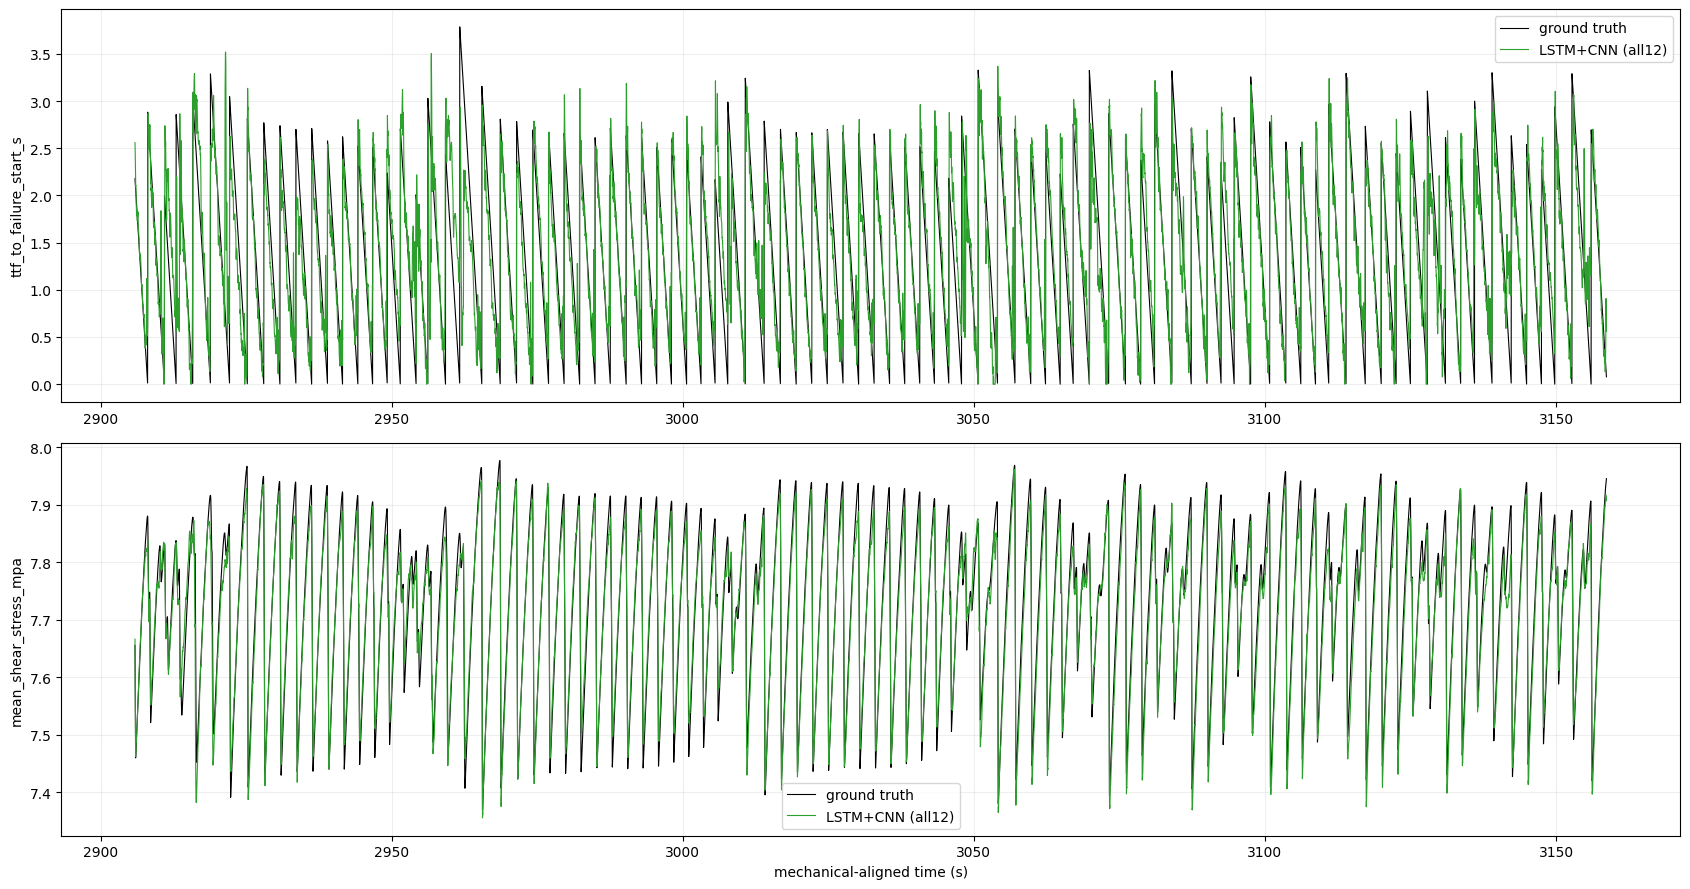

saved: /content/drive/MyDrive/MLStressDrop/p5986/colab_outputs_p5986/07_LSTM_CNN_metadata_p5986.json


In [ ]:
# Pick the LSTM experiment with the smallest validation MSE for each target — never by test score.
chosen = (
    training_manifest.sort_values('best_validation_mse_scaled')
    .groupby('target', as_index=False)
    .first()
)
fig, axes = plt.subplots(len(TARGETS), 1, figsize=(17, 9), sharex=False)
if len(TARGETS) == 1:
    axes = [axes]
for ax, target_name in zip(axes, TARGETS):
    experiment_key = chosen.loc[chosen['target'] == target_name, 'experiment'].iloc[0]
    plot_data = final_predictions[
        (final_predictions['target'] == target_name)
        & (final_predictions['experiment'] == experiment_key)
    ]
    stride = max(1, len(plot_data) // 12_000)
    plot_data = plot_data.iloc[::stride]
    ax.plot(plot_data['window_center_s'], plot_data['y_true'], color='black', lw=0.8, label='ground truth')
    ax.plot(plot_data['window_center_s'], plot_data['prediction_lstm_cnn'], color='tab:green', lw=0.8, label=f'LSTM+CNN ({experiment_key})')
    ax.set_ylabel(target_name)
    ax.grid(alpha=0.2)
    ax.legend()
axes[-1].set_xlabel('mechanical-aligned time (s)')
plt.tight_layout()
plt.show()

metadata = {
    'experiment': 'p5986',
    'run': 'run1',
    'notebook': '07_p5986_LSTM_CNN_TTF_shear_stress',
    'paper_architecture': 'BatchNorm -> LSTM128 -> Conv1D 128/84/64 k=2 -> Flatten -> Dense64/32 -> Dense1',
    'github_repository': 'lauralaurenti/DNN-earthquake-prediction-forecasting',
    'github_commit_read': '6252dcf9a43dae42cb5d1cbf641ba3f6dd4cbb76',
    'github_corrections': [
        'fit feature and target scaling on training only',
        'separate validation cycles',
        'no per-epoch test evaluation',
        'separate target scalers and separate models',
        'linear stress output; nonnegative TTF output',
    ],
    'sequence_length': SEQUENCE_LENGTH,
    'sequence_duration_s': SEQUENCE_LENGTH * step_seconds,
    'learning_rate': LEARNING_RATE,
    'batch_size': BATCH_SIZE,
    'max_epochs': MAX_EPOCHS,
    'early_stopping_patience': EARLY_STOPPING_PATIENCE,
    'sensor_sets': SENSOR_SETS,
    'selected_pair_method': 'user physical override' if 'selection' in sensor_ranking.columns else 'Ridge proxy ranked on training/validation only',
    'targets': TARGETS,
    'split': database_metadata['split'],
    'stress_target_mode': database_metadata['targets']['primary_stress_mode'],
    'scalers_training_only': scaler_manifest,
    'training_manifest': training_manifest.to_dict('records'),
    'final_outputs': [str(metrics_path), str(predictions_path)] + xgb_models,
}
metadata_path = OUT_DIR / '07_LSTM_CNN_metadata_p5986.json'
metadata_path.write_text(json.dumps(metadata, indent=2), encoding='utf-8')
print('saved:', metadata_path)
